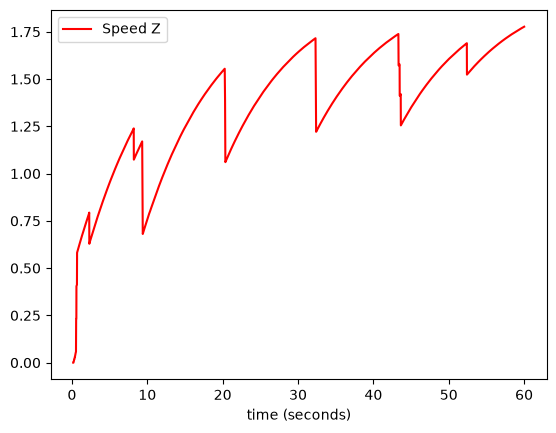

In [4]:

import random
import arslabrobotics as ar

dp = ar.data.DataPlotter()
dp.set_x("time (seconds)")
dp.add_y("vz", "Speed Z")

dds = ar.dds.DDS()
dds.start()

dds.subscribe(['VZ'])
f = 2.5
dds.publish('f1', f, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f2', f, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f3', f, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f4', f, ar.dds.DDS_TYPE_FLOAT)

data_file = open("drone_z_data_%d.txt" % (int(f*10)), "w")

t = ar.utils.Time(use_fake_time = False)

t.start()
while t.get() < 60:
    vz = dds.wait('VZ')
    delta_t = t.elapsed()
    #print(delta_t)
    dds.publish('time', t.get(), ar.dds.DDS_TYPE_FLOAT)
    
    dp.append_x(t.get())
    dp.append_y("vz", vz)

    data_file.write(f"{f} {vz}\n")

dp.plot()
data_file.close()
dds.publish('f1', 0, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f2', 0, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f3', 0, ar.dds.DDS_TYPE_FLOAT)
dds.publish('f4', 0, ar.dds.DDS_TYPE_FLOAT)
dds.stop()
